# 04 - Clusters and marker genes

Notebook 03 showed every model struggles with the CD4 T-cell subtypes. Is that the models' fault, or do those cells genuinely look alike?

Two checks that don't use the models at all:

1. **Clustering**: group cells by expression alone, without looking at the labels, then compare the groups to the labels.
2. **Marker genes**: check that each label's cells switch on the textbook genes for that cell type.

Steps: load data -> UMAP + Leiden clustering -> compare clusters to labels -> marker gene dot plot.

In [1]:
# Load the tools I need
import scanpy as sc                                 # single-cell analysis
import pandas as pd                                 # tables
import matplotlib.pyplot as plt                     # plots
from sklearn.metrics import adjusted_rand_score     # how well two groupings agree

# Same dataset as notebooks 01-03
adata = sc.datasets.pbmc68k_reduced()

## UMAP and Leiden clustering

The dataset already has a PCA and a **neighbor graph** (a network linking each cell to the cells most similar to it), so we can skip those steps.

- **UMAP** squeezes 765 genes into 2 dimensions so we can draw the cells. Close dots = similar cells.
- **Leiden** finds communities in the neighbor graph: groups of cells more connected to each other than to the rest. It never sees the labels.

In [2]:
# 2-D layout for plotting; random_state makes it the same every run
sc.tl.umap(adata, random_state=0)

# Find clusters in the neighbor graph; results go in adata.obs["leiden"]
sc.tl.leiden(adata, flavor="igraph", n_iterations=2, random_state=0)

print("Number of clusters:", adata.obs["leiden"].nunique())

Number of clusters: 12


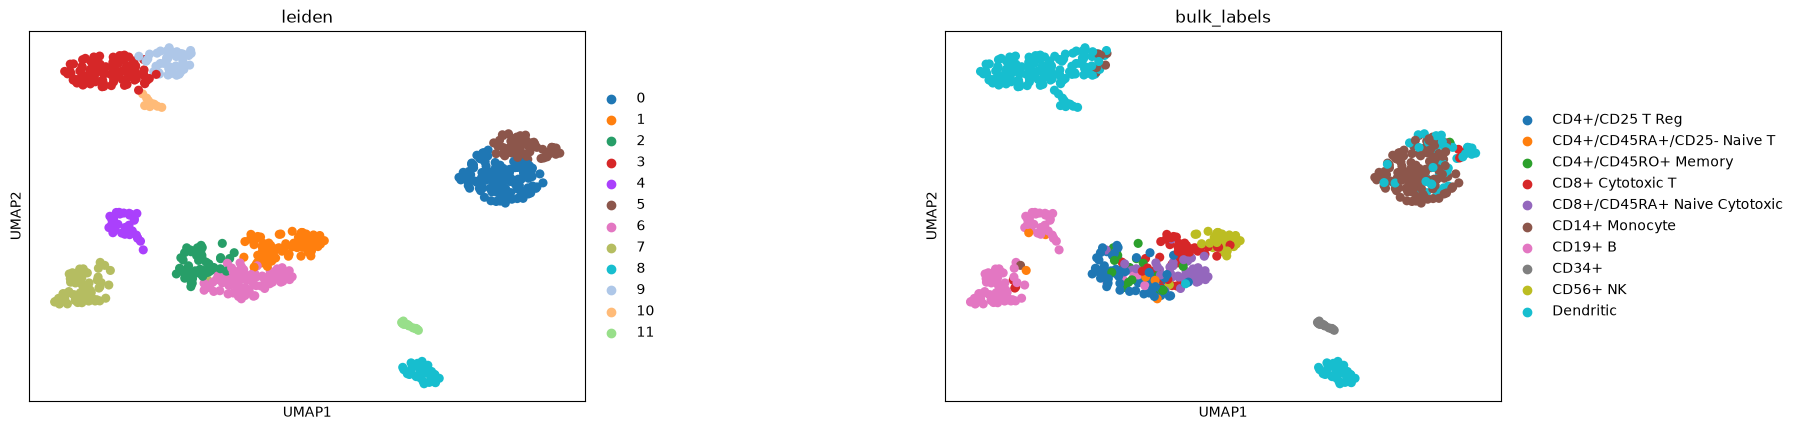

In [3]:
# Left: clusters found from expression alone. Right: the labels the models learned.
# If the two pictures match, the labels agree with the data.
sc.pl.umap(adata, color=["leiden", "bulk_labels"], wspace=0.5)  # wspace = gap between the plots

## Which labels land in which cluster?

A **crosstab** counts cells for every cluster-label pair. A clean cluster has almost all its cells in one column.

The **adjusted Rand index (ARI)** sums it up in one number: 1 = clusters and labels agree perfectly, 0 = no better than random.

In [4]:
# Rows = clusters, columns = labels, numbers = cells
counts = pd.crosstab(adata.obs["leiden"], adata.obs["bulk_labels"])
counts

bulk_labels,CD4+/CD25 T Reg,CD4+/CD45RA+/CD25- Naive T,CD4+/CD45RO+ Memory,CD8+ Cytotoxic T,CD8+/CD45RA+ Naive Cytotoxic,CD14+ Monocyte,CD19+ B,CD34+,CD56+ NK,Dendritic
leiden,,,,,,,,,,
0,0,0,0,0,0,100,0,0,0,22
1,1,0,1,35,7,0,0,0,30,0
2,37,2,7,4,7,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,104
4,0,2,0,0,0,0,30,0,0,0
5,0,0,1,3,0,22,0,0,0,30
6,30,3,10,9,29,0,3,0,1,1
7,0,1,0,3,0,1,62,0,0,0
8,0,0,0,0,0,0,0,0,0,35


In [5]:
# What share of each cluster is its most common label? (1.00 = perfectly clean)
purity = counts.max(axis=1) / counts.sum(axis=1)
pd.DataFrame({"cells": counts.sum(axis=1),
              "main label": counts.idxmax(axis=1),
              "purity": purity.round(2)})

,cells,main label,purity
leiden,,,
0,122,CD14+ Monocyte,0.82
1,74,CD8+ Cytotoxic T,0.47
2,57,CD4+/CD25 T Reg,0.65
3,104,Dendritic,1.00
4,32,CD19+ B,0.94
5,56,Dendritic,0.54
6,86,CD4+/CD25 T Reg,0.35
7,67,CD19+ B,0.93
8,35,Dendritic,1.00


In [6]:
# One summary number for the whole comparison
ari = adjusted_rand_score(adata.obs["bulk_labels"], adata.obs["leiden"])
print("Adjusted Rand index:", round(ari, 2))

Adjusted Rand index: 0.4


## Marker genes

A **marker gene** is switched on in one cell type and mostly off in others (for example, MS4A1 in B cells). If each label's cells express its expected markers, the label is believable.

Catch: this dataset keeps only 765 of ~20,000 genes, so some markers may be missing. We check before plotting.

In [7]:
# Textbook markers: gene -> the cell type it points to
markers = {
    "CD3E": "all T cells",
    "CD8A": "CD8 T cells",
    "IL7R": "CD4 T cells",
    "CCR7": "naive / central memory T cells",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD14": "classical monocytes",
    "LYZ": "monocytes and dendritic cells",
    "FCGR3A": "NK cells and non-classical monocytes",
    "NKG7": "NK and cytotoxic T cells",
    "GNLY": "NK and cytotoxic T cells",
    "FCER1A": "dendritic cells",
    "CST3": "monocytes and dendritic cells",
    "CD34": "stem / progenitor cells",
}

# Only 765 genes were kept, so check which markers are actually present
present = [gene for gene in markers if gene in adata.var_names]
missing = [gene for gene in markers if gene not in adata.var_names]
print("Present:", present)
print("Missing:", missing)

Present: ['CD3E', 'CD8A', 'IL7R', 'CCR7', 'MS4A1', 'CD79A', 'LYZ', 'FCGR3A', 'NKG7', 'GNLY', 'FCER1A', 'CST3']
Missing: ['CD14', 'CD34']


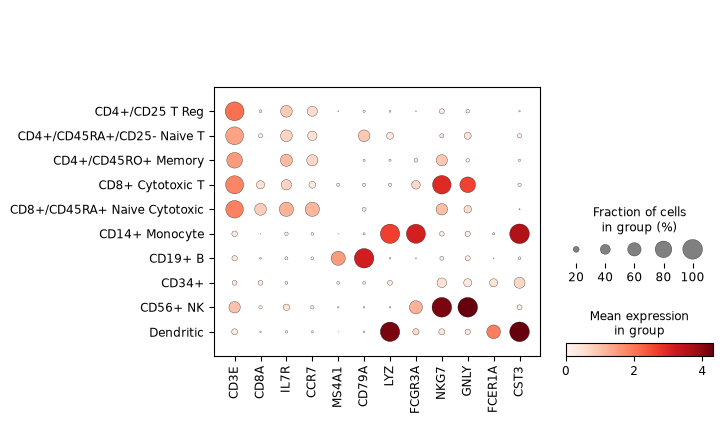

In [8]:
# One row per label, one column per marker.
# Dot size = % of cells in that label expressing the gene; color = how strongly.
# Scanpy uses adata.raw (log-normalized counts) for this plot automatically.
sc.pl.dotplot(adata, present, groupby="bulk_labels")

## What I learned

_(Fill this in after reading the results above.)_

- Which labels form clean clusters? Which share clusters?
- Do those mixed labels match the types the models got wrong in notebook 03?
- Which markers confirm each label? Is there any marker that separates the CD4 T-cell subtypes?